# 03 - AI Business Intelligence: Sales Forecasting

এখানে chronological holdout দিয়ে baseline forecasting পরীক্ষা করা হবে। Store Sales-এর জন্য daily total sales-এর 7-day seasonal-naive baseline এবং Online Retail-এর জন্য monthly net-revenue-এর previous-month baseline ব্যবহার করা হবে। MAE/RMSE দিয়ে evaluate করে actual বনাম predicted chart দেখানো হবে। এটি baseline; ভালো ফল নিশ্চিত নয় এবং এটি production model নয়।

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def find_data_dir():
    roots = [Path.cwd(), *Path.cwd().parents]
    for root in roots:
        for candidate in (root / 'dataset', root / 'notebooks' / 'dataset', root / 'ai-service' / 'notebooks'):
            if (candidate / 'train.csv').is_file() or (candidate / 'Online Retail.xlsx').is_file():
                return candidate
    raise FileNotFoundError('Expected datasets in notebooks/dataset.')

DATA_DIR = find_data_dir()
print(f'Dataset folder: {DATA_DIR}')

Dataset folder: e:\9th semi\AI Project\ai-service\notebooks\dataset


## Reusable chronological holdout evaluation

In [2]:
def evaluate_naive(series, lag, validation_periods, label):
    series = series.astype(float).sort_index()
    if len(series) <= lag + 1:
        print(f'{label}: insufficient history ({len(series)} periods; need more than {lag + 1}).')
        return None
    validation_periods = min(validation_periods, len(series) - lag - 1)
    split = len(series) - validation_periods
    actual = series.iloc[split:]
    predicted = series.shift(lag).iloc[split:]
    valid = actual.notna() & predicted.notna()
    actual = actual.loc[valid]
    predicted = predicted.loc[valid]
    if actual.empty:
        print(f'{label}: no valid holdout predictions could be made.')
        return None
    errors = actual.to_numpy() - predicted.to_numpy()
    metrics = {
        'dataset': label,
        'baseline': f'lag-{lag} naive',
        'train_periods': split,
        'validation_periods': len(actual),
        'MAE': float(np.mean(np.abs(errors))),
        'RMSE': float(np.sqrt(np.mean(errors ** 2))),
    }
    predictions = pd.DataFrame({'actual': actual, 'predicted': predicted})
    return metrics, predictions

def show_forecast(result, title, ylabel):
    if result is None:
        return
    metrics, predictions = result
    display(pd.DataFrame([metrics]).set_index('dataset'))
    fig, ax = plt.subplots(figsize=(13, 5))
    predictions['actual'].plot(ax=ax, marker='o', label='Actual')
    predictions['predicted'].plot(ax=ax, marker='o', label='Predicted')
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.legend()
    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()
    return predictions

## Store Sales: daily seasonal-naive forecast

The validation is chronological. The 7-day baseline predicts each validation date from the same weekday one week earlier. This is a rolling one-step-ahead baseline: prior observed values are available as the validation period advances.

,baseline,train_periods,validation_periods,MAE,RMSE
dataset,,,,,
Store Sales daily total,lag-7 naive,1598,90,93934.85,122634.692798


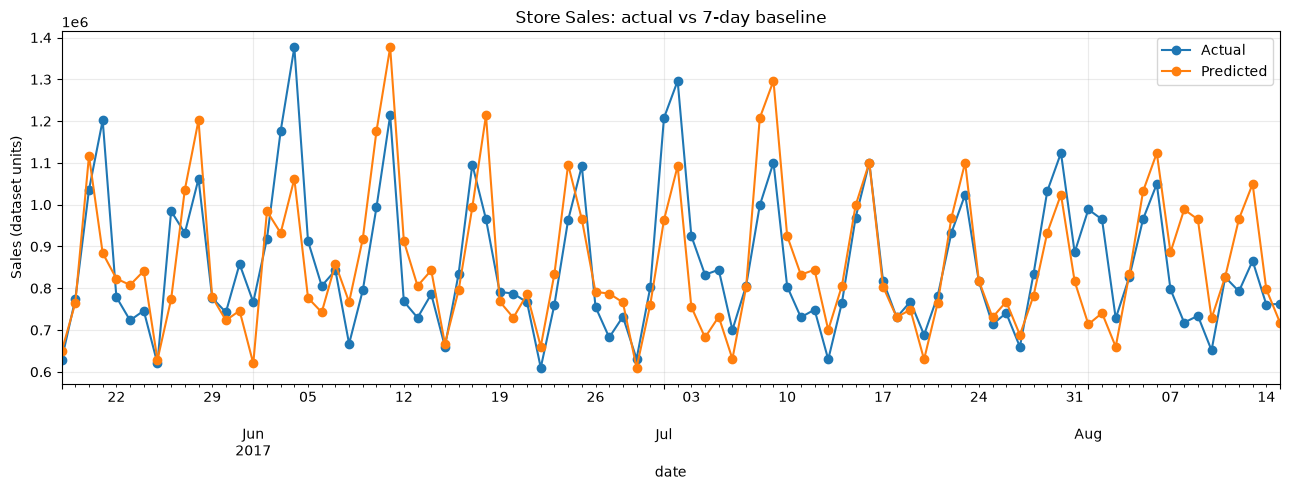

In [3]:
train_path = DATA_DIR / 'train.csv'
if not train_path.is_file():
    print('train.csv is missing; Store Sales forecast skipped.')
else:
    store_train = pd.read_csv(
        train_path, usecols=['date', 'sales'], parse_dates=['date'],
        dtype={'sales': 'float32'}, low_memory=False,
    )
    daily_store_sales = (
        store_train.groupby('date')['sales'].sum()
        .sort_index().resample('D').sum().fillna(0)
    )
    validation_days = min(90, max(14, len(daily_store_sales) // 5))
    store_result = evaluate_naive(
        daily_store_sales, lag=7, validation_periods=validation_days,
        label='Store Sales daily total',
    )
    show_forecast(store_result, 'Store Sales: actual vs 7-day baseline', 'Sales (dataset units)')

## Online Retail: previous-month revenue baseline

Monthly net revenue includes negative return/cancellation lines. The validation split is chronological and uses the prior month as a simple baseline. If the file has too little history, the notebook reports that instead of fabricating a score.

,baseline,train_periods,validation_periods,MAE,RMSE
dataset,,,,,
Online Retail monthly net revenue,lag-1 naive,10,3,490052.289333,635738.286465


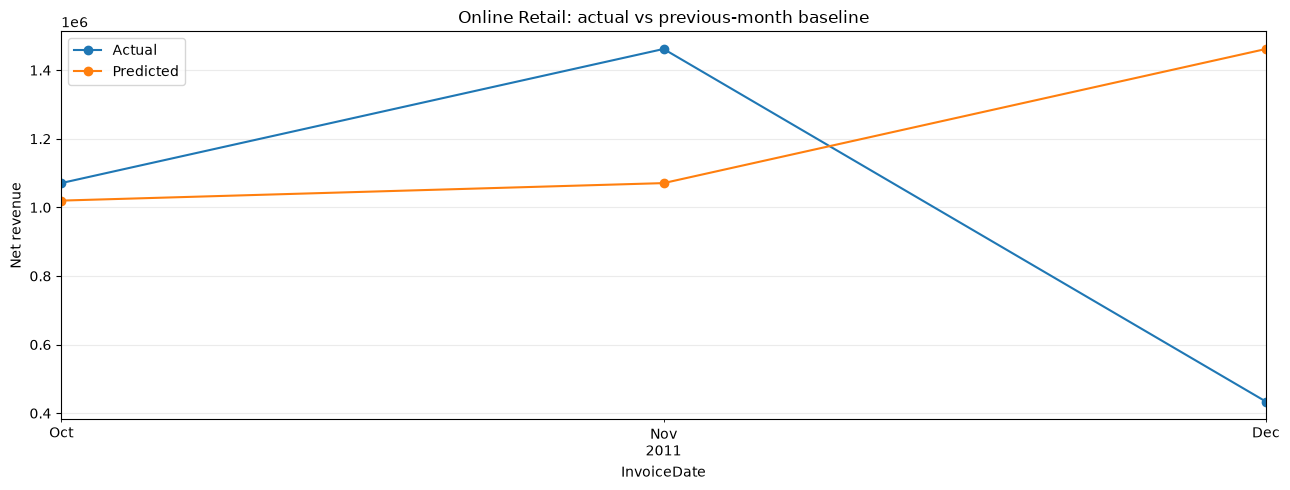

In [4]:
retail_path = DATA_DIR / 'Online Retail.xlsx'
if not retail_path.is_file():
    print('Online Retail.xlsx is missing; retail forecast skipped.')
else:
    retail = pd.read_excel(retail_path, usecols=['InvoiceDate', 'Quantity', 'UnitPrice'])
    retail['InvoiceDate'] = pd.to_datetime(retail['InvoiceDate'], errors='coerce')
    retail['Quantity'] = pd.to_numeric(retail['Quantity'], errors='coerce')
    retail['UnitPrice'] = pd.to_numeric(retail['UnitPrice'], errors='coerce')
    retail['line_revenue'] = retail['Quantity'] * retail['UnitPrice']
    retail_monthly_net = (
        retail.dropna(subset=['InvoiceDate'])
        .set_index('InvoiceDate')['line_revenue']
        .resample('MS').sum().sort_index()
    )
    retail_result = evaluate_naive(
        retail_monthly_net, lag=1, validation_periods=3,
        label='Online Retail monthly net revenue',
    )
    show_forecast(retail_result, 'Online Retail: actual vs previous-month baseline', 'Net revenue')

## Optional: create a Store Sales test-set prediction preview

`test.csv` and `sample_submission.csv` do not contain observed sales labels, so they cannot be used to calculate MAE/RMSE. This section applies a clearly labeled 7-day seasonal-naive baseline to the competition test rows and displays a preview only; it does not write or submit a file.

In [5]:
test_path = DATA_DIR / 'test.csv'
if not train_path.is_file() or not test_path.is_file():
    print('train.csv or test.csv is missing; test-set prediction preview skipped.')
else:
    history_frame = pd.read_csv(
        train_path, usecols=['date', 'store_nbr', 'family', 'sales'],
        parse_dates=['date'],
        dtype={'store_nbr': 'int16', 'family': 'category', 'sales': 'float32'},
        low_memory=False,
    )
    test_frame = pd.read_csv(
        test_path, usecols=['date', 'store_nbr', 'family'],
        parse_dates=['date'],
        dtype={'store_nbr': 'int16', 'family': 'category'},
        low_memory=False,
    )
    if {'date', 'store_nbr', 'family', 'sales'}.issubset(history_frame.columns) and \
       {'date', 'store_nbr', 'family'}.issubset(test_frame.columns):
        history_by_date = {
            date: group.set_index(['store_nbr', 'family'])['sales']
            for date, group in history_frame.groupby('date', observed=True)
        }
        recent_history = history_frame.sort_values('date').groupby(
            ['store_nbr', 'family'], observed=True
        ).tail(28)
        fallback_by_series = recent_history.groupby(
            ['store_nbr', 'family'], observed=True
        )['sales'].mean()
        fallback_global = float(history_frame['sales'].mean())
        prediction_parts = []
        for forecast_date in sorted(test_frame['date'].dropna().unique()):
            day_rows = test_frame.loc[test_frame['date'].eq(forecast_date),
                                      ['date', 'store_nbr', 'family']].copy()
            series_keys = pd.MultiIndex.from_frame(day_rows[['store_nbr', 'family']])
            lag_date = pd.Timestamp(forecast_date) - pd.Timedelta(days=7)
            source = history_by_date.get(lag_date)
            values = source.reindex(series_keys).to_numpy(dtype=float) if source is not None else np.full(len(day_rows), np.nan)
            fallback = fallback_by_series.reindex(series_keys).to_numpy(dtype=float)
            values = np.where(np.isfinite(values), values, fallback)
            values = np.where(np.isfinite(values), values, fallback_global)
            day_rows['sales_prediction'] = np.maximum(values, 0)
            prediction_parts.append(day_rows)
            history_by_date[pd.Timestamp(forecast_date)] = pd.Series(
                day_rows['sales_prediction'].to_numpy(), index=series_keys
            )
        test_predictions = pd.concat(prediction_parts, ignore_index=True)
        print(f'Prediction rows: {len(test_predictions):,}')
        display(test_predictions.head(20))
        display(test_predictions.groupby('date')['sales_prediction'].sum().head(10))
    else:
        print('Required columns are missing; test-set prediction preview skipped.')

Prediction rows: 28,512


,date,store_nbr,family,sales_prediction
0,2017-08-16,1,AUTOMOTIVE,7.000000
1,2017-08-16,1,BABY CARE,0.000000
2,2017-08-16,1,BEAUTY,4.000000
3,2017-08-16,1,BEVERAGES,2311.000000
4,2017-08-16,1,BOOKS,0.000000
5,2017-08-16,1,BREAD/BAKERY,399.546997
6,2017-08-16,1,CELEBRATION,12.000000
7,2017-08-16,1,CLEANING,651.000000
8,2017-08-16,1,DAIRY,789.000000
9,2017-08-16,1,DELI,123.496002


date
2017-08-16    734139.674935
2017-08-17    651386.911396
2017-08-18    826373.720315
2017-08-19    792630.535783
2017-08-20    865639.676976
2017-08-21    760922.405580
2017-08-22    762661.935845
2017-08-23    734139.674935
2017-08-24    651386.911396
2017-08-25    826373.720315
Name: sales_prediction, dtype: float64

## Interpretation

- Compare MAE/RMSE only between models evaluated on the same target, time split, and units.
- These baselines do not include store/product features, holidays, oil prices, or promotions; they are reference scores for future model work.
- `test.csv` has no true target in this project folder, so its predictions are a preview and cannot establish model accuracy.
- Forecast performance on historical holdout does not guarantee future performance.